<h1> TP2 - Analyse en composantes principales, classification et reconstruction</h1>

<h2> Introduction </h2>

L'analyse en composantes principales (ACP) est une technique fondamentale de réduction de dimensionnalité largement utilisée en apprentissage automatique et en analyse de données. Dans le contexte de la reconnaissance faciale, cette méthode présente un double intérêt : d'une part, elle permet de réduire significativement la complexité computationnelle des algorithmes de classification, et d'autre part, elle offre des possibilités de compression d'images avec reconstruction.

Ce travail pratique s'inscrit dans la continuité du TP1 sur la classification par k-plus proches voisins (k-PPV) et vise à explorer les applications de l'ACP sur la base de données de visages "Labeled Faces in the Wild". 

<h3>Ajout du code fourni et import des libraries nécessaires </h3>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score
from PIL import Image
from sklearn.decomposition import PCA
from skimage.color import rgb2gray
import seaborn as sns
import time


def plotHistoClasses(labels):
    """Affiche l'histogramme des classes"""
    unique, counts = np.unique(labels, return_counts=True)
    plt.figure(figsize=(10, 6))
    plt.bar(unique, counts)
    plt.xlabel('Classes')
    plt.ylabel('Nombre d\'exemples')
    plt.title('Distribution des classes')
    plt.show()
    return unique, counts

def plotGallery(images, titles=None, h=62, w=47, n_row=3, n_col=4):
    """Affiche une galerie d'images"""
    plt.figure(figsize=(1.8 * n_col, 2.4 * n_row))
    plt.subplots_adjust(bottom=0, left=.01, right=.99, top=.90, hspace=.35)
    for i in range(min(n_row * n_col, len(images))):
        plt.subplot(n_row, n_col, i + 1)
        plt.imshow(images[i].reshape((h, w)), cmap=plt.cm.gray)
        if titles is not None:
            plt.title(titles[i], size=12)
        plt.xticks(())
        plt.yticks(())
    plt.show()

<h2>I. Chargement et mise en forme des données </h2>

Données chargées avec succès!
Forme de X: (1288, 62, 47)
Forme de y: (1288,)
Noms des classes: ['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Tony Blair']

Affichage de la galerie d'images...


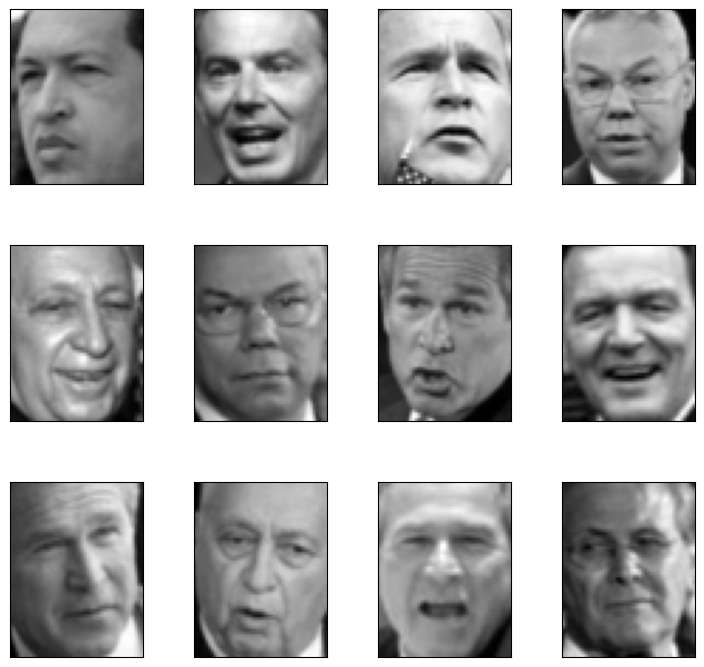


Affichage de l'histogramme des classes...


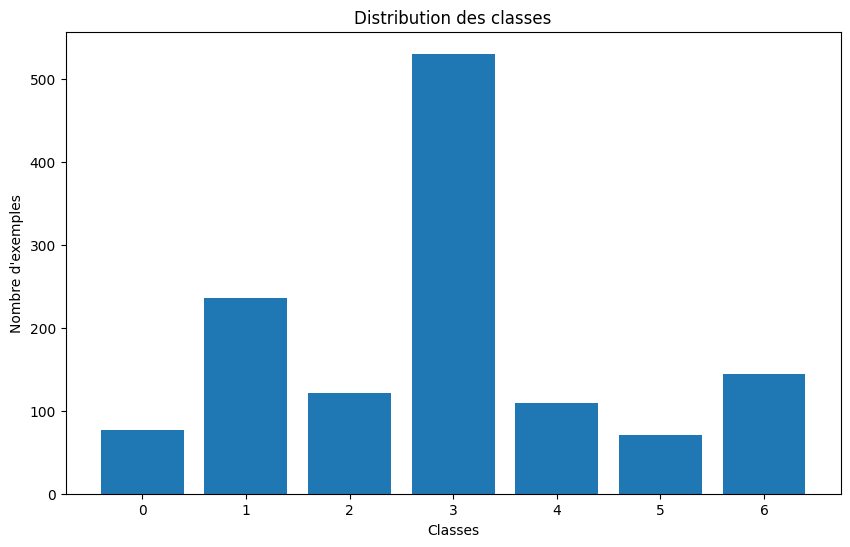

In [2]:
[X, y, name] = np.load("TP2.npy", allow_pickle=True)

print(f"Données chargées avec succès!")
print(f"Forme de X: {X.shape}")
print(f"Forme de y: {y.shape}")
print(f"Noms des classes: {name}")


print("\nAffichage de la galerie d'images...")
plotGallery(X[:12]) 

print("\nAffichage de l'histogramme des classes...")
unique_classes, class_counts = plotHistoClasses(y)

<h3>Questions</h3>

In [3]:
RANDOM_STATE = 24092025 # J'utilise la date d'aujourd'hui comme random_state
# Partitionnement (identique au TP1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

n_features = X_train.shape[1] * X_train.shape[2]
X_train_flat = X_train.reshape(X_train.shape[0], n_features)
X_test_flat = X_test.reshape(X_test.shape[0], n_features)

# Standardisation
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_flat)
X_test_scaled = scaler.transform(X_test_flat)

print(f"\nRéponse aux questions I:")
print(f"- Données en apprentissage: {X_train.shape[0]}")
print(f"- Données en test: {X_test.shape[0]}")
print(f"- Dimension après redimensionnement: {n_features} (62 x 47)")


Réponse aux questions I:
- Données en apprentissage: 966
- Données en test: 322
- Dimension après redimensionnement: 2914 (62 x 47)


<h2>II. Analyse en composantes principales et classification </h2>

<h4>a. Définition de l'ACP</h4>

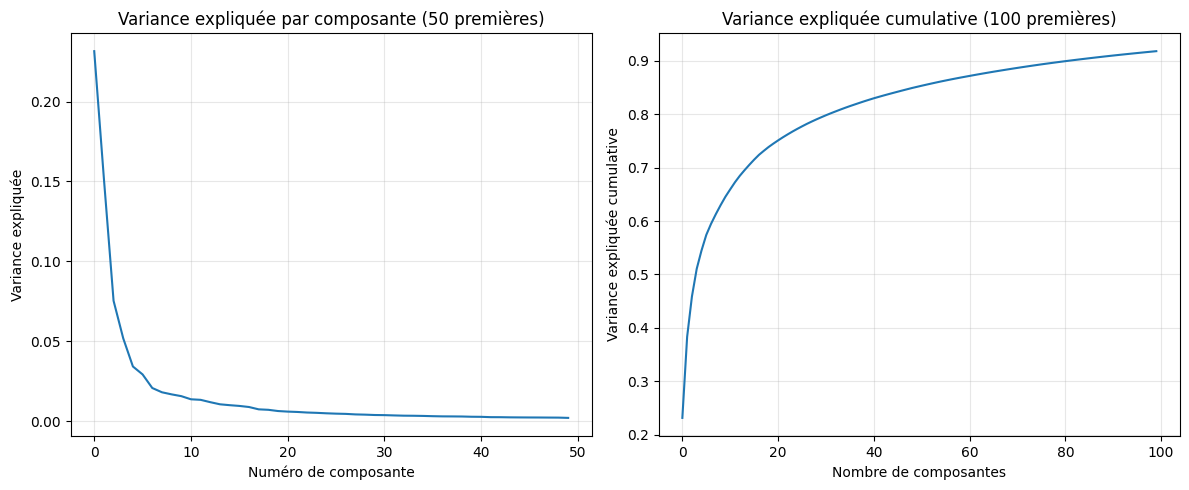

In [4]:
pca_full = PCA(n_components=966)
pca_full.fit(X_train_scaled)

# Tracer les variances expliquées
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(pca_full.explained_variance_ratio_[:50])
plt.xlabel('Numéro de composante')
plt.ylabel('Variance expliquée')
plt.title('Variance expliquée par composante (50 premières)')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(np.cumsum(pca_full.explained_variance_ratio_)[:100])
plt.xlabel('Nombre de composantes')
plt.ylabel('Variance expliquée cumulative')
plt.title('Variance expliquée cumulative (100 premières)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


<h4>b. Redéfinition de l'ACP</h4>

In [5]:
pca_100 = PCA(n_components=100)
pca_100.fit(X_train_scaled)

# Transformer les données
X_train1 = pca_100.transform(X_train_scaled)
X_test1 = pca_100.transform(X_test_scaled)

print(f"- Taille de X_train1: {X_train1.shape}")
print(f"- Taille de X_test1: {X_test1.shape}")
print(f"- Nouvelle dimension des données: {X_train1.shape[1]}")

- Taille de X_train1: (966, 100)
- Taille de X_test1: (322, 100)
- Nouvelle dimension des données: 100


<h4>c. Classification 5PPV avec la distance de Manhattan</h4>

<h5>Classification sur les données originales:</h5>

In [6]:


tps1 = time.time()
knn_original = KNeighborsClassifier(n_neighbors=5, metric='manhattan')
knn_original.fit(X_train_scaled, y_train)
y_pred_original = knn_original.predict(X_test_scaled)
tps2 = time.time()

accuracy_original = accuracy_score(y_test, y_pred_original)
time_original = tps2 - tps1

print(f"- Taux de reconnaissance: {accuracy_original:.4f} ({accuracy_original*100:.2f}%)")
print(f"- Durée de classification: {time_original:.4f} secondes")


- Taux de reconnaissance: 0.6180 (61.80%)
- Durée de classification: 0.5211 secondes


<h5>Classification sur les données avec ACP (100 composantes):</h5>

In [7]:
tps1 = time.time()
knn_pca = KNeighborsClassifier(n_neighbors=5, metric='manhattan')
knn_pca.fit(X_train1, y_train)
y_pred_pca = knn_pca.predict(X_test1)
tps2 = time.time()

accuracy_pca = accuracy_score(y_test, y_pred_pca)
time_pca = tps2 - tps1

print(f"- Taux de reconnaissance: {accuracy_pca:.4f} ({accuracy_pca*100:.2f}%)")
print(f"- Durée de classification: {time_pca:.4f} secondes")


- Taux de reconnaissance: 0.6894 (68.94%)
- Durée de classification: 0.0212 secondes


<h4> Questions </h4>

- Les valeurs renvoyées par pca.explained_variance_ratio_ représente les valeurs propres. C'est aussi la proportion de variance

- La taille de X_train1 est: (966, 100) et celle de X_test1 est: (322, 100). La nouvelle dimension des données est: 100.

- Variation du temps de calcul: Le temps de calcul avec ACP est de 0.0183 secondes contre 0.4605s sans ACP. En plus de ça, la précision avec ACP est de 68.01% contre 61.80% sans ACP. Non seulement on a un gain de temps mais, on a en plus un gain en précision.

<h2>III. Analyse en composantes principales et reconstruction</h2>

Le but est de compresser les images afin qu’elles prennennt moins de place en mémoire. On va 
donc  définir  sur  X_train  la  façon  de  compresser.  Puis  on  comprimera  et  décomprimera  les 
images de X_test afin de voir les pertes induites par la compression.

<h4>a. Définition de l'ACP avec 50 composantes</h4>

In [8]:
pca_50 = PCA(n_components=50)
pca_50.fit(X_train_scaled)


,n_components,50
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


<h4>b. Récupérer les vecteurs propres en conservant 50 composantes et ajustons le modèle sur X_train</h4>

- Forme des vecteurs propres: (50, 2914)
- Taille de chaque vecteur propre: 2914
Affichage des images propres (eigenfaces):


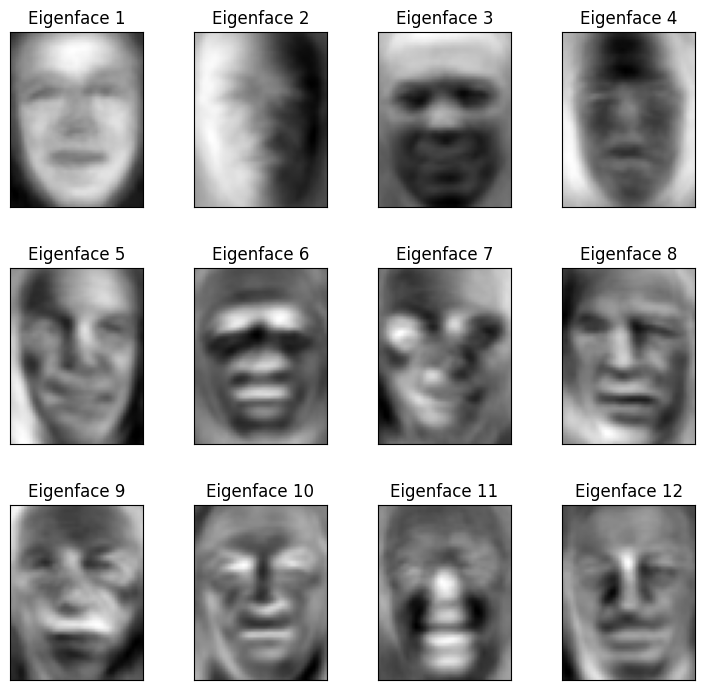

In [9]:
# Récupérer les vecteurs propres (composantes principales)
eigenvectors = pca_50.components_  # Shape: (50, 2914)
print(f"- Forme des vecteurs propres: {eigenvectors.shape}")
print(f"- Taille de chaque vecteur propre: {eigenvectors.shape[1]}")

# Redimensionner les vecteurs propres en images propres
eigenfaces = eigenvectors.reshape(50, 62, 47)

print(f"Affichage des images propres (eigenfaces):")
plotGallery(eigenfaces[:12], 
           titles=[f'Eigenface {i+1}' for i in range(12)],
           n_row=3, n_col=4)

<h4>Réponses aux questions</h4>

- Les vecteurs propres représentent les directions principales de variation dans l'espace de données.
- Leur taille est de 2914

<h4>c. Compression des images </h4>

In [10]:
X_test_comp = pca_50.transform(X_test_scaled)
print(f"- Taille de X_test: {X_test_scaled.shape}")
print(f"- Taille de X_test_comp: {X_test_comp.shape}")

- Taille de X_test: (322, 2914)
- Taille de X_test_comp: (322, 50)


<h4>d. Reconstruction des images contenues dans X_test_comp ... et comparaison visuelle</h4>

- Taille de X_test_reconst: (322, 2914)
Comparaison visuelle des images originales et reconstruites:


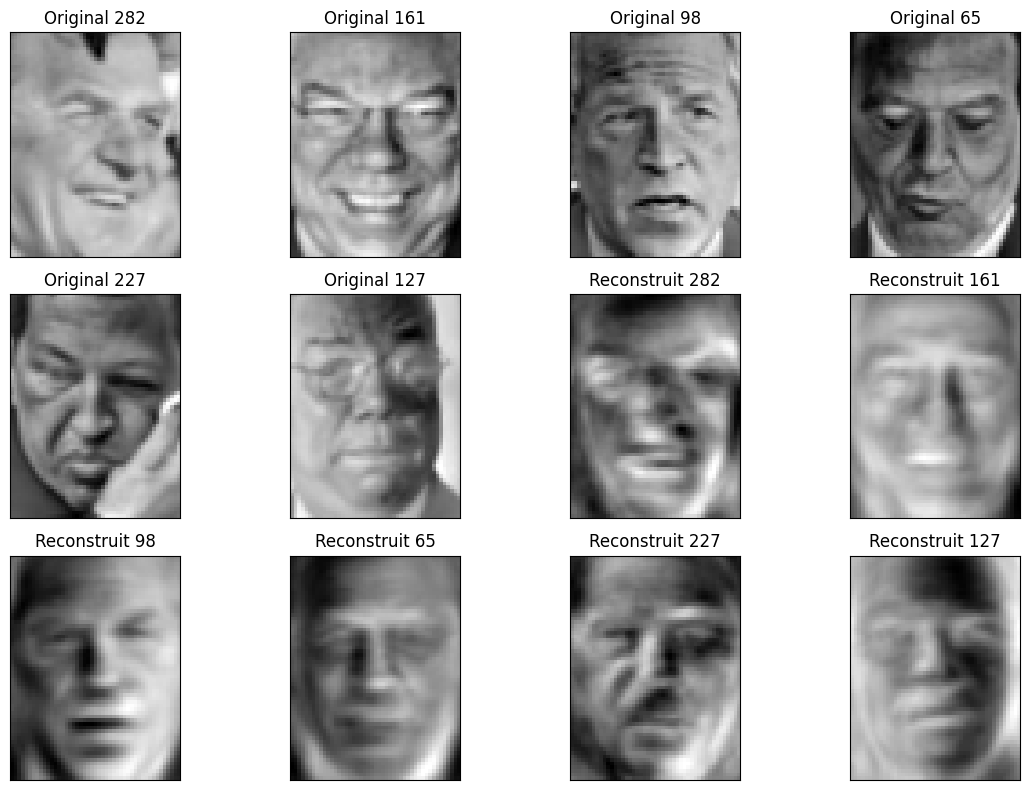

In [11]:
X_test_reconst = pca_50.inverse_transform(X_test_comp)
print(f"- Taille de X_test_reconst: {X_test_reconst.shape}")

# Affichage comparatif des images
print(f"Comparaison visuelle des images originales et reconstruites:")

# Sélectionner quelques images pour la comparaison
n_images = 6
indices = np.random.choice(len(X_test_scaled), n_images, replace=False)

# Images originales
plt.figure(figsize=(12, 8))
for i, idx in enumerate(indices):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test_scaled[idx].reshape(62, 47), cmap='gray')
    plt.title(f'Original {idx}')
    plt.xticks([])
    plt.yticks([])

# Images reconstruites
for i, idx in enumerate(indices):
    plt.subplot(3, 4, i + 7)
    plt.imshow(X_test_reconst[idx].reshape(62, 47), cmap='gray')
    plt.title(f'Reconstruit {idx}')
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

<h4>e. Comparaison des images initiales et reconstruites de manière quantitative en faisant la moyenne des distances euclidiennes</h4>

In [12]:
# Calcul de l'erreur de reconstruction
E = (X_test_reconst - X_test_scaled)**2
reconstruction_error = np.mean(np.sqrt(np.sum(E, axis=1)))
print(f"Erreur de reconstruction moyenne: {reconstruction_error:.4f}")


Erreur de reconstruction moyenne: 21.9439


Qualitativement, l'erreur de reconstruction moyenne est de 21.9493

<h3> Questions </h3>

- La taille de X_test est de: (322 x 2914); celle de X_test_comp est de (322 x 50)
- Principe de reconstruction: utiliser inverse_transform() de PCA. X_test_comp contient les coefficients dans la base des composantes principales; la reconstruction combine ces coefficients avec les vecteurs propres
- Passage X_test_comp → X_test_reconst: transformation inverse

<h4>f. Faire varier le nombre de composantes conservées de 10 à 950 par pas de 50 et calculer l'erreur de reconstruction. Ensuite, afficher l'erreur de reconstruction en fonction du nombre de composantes. </h4>

Calcul des erreurs de reconstruction pour différents nombres de composantes:
  10 composantes: erreur = 31.5000
  110 composantes: erreur = 17.0311
  210 composantes: erreur = 13.1200
  310 composantes: erreur = 10.8845
  410 composantes: erreur = 9.3913
  510 composantes: erreur = 8.3071
  610 composantes: erreur = 7.4859
  710 composantes: erreur = 6.8253
  810 composantes: erreur = 6.2999
  910 composantes: erreur = 5.8711


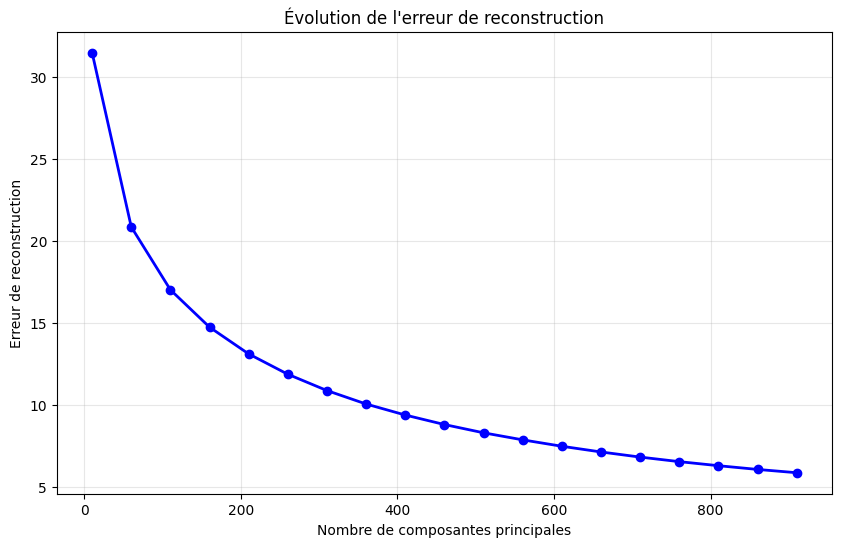

In [ ]:
# Variation du nombre de composantes

components_range = range(10, 951, 50)
reconstruction_errors = []

print("Calcul des erreurs de reconstruction pour différents nombres de composantes:")
for n_comp in components_range:
    if n_comp <= min(X_train_scaled.shape):
        pca_temp = PCA(n_components=n_comp)
        pca_temp.fit(X_train_scaled)
        X_temp_comp = pca_temp.transform(X_test_scaled)
        X_temp_reconst = pca_temp.inverse_transform(X_temp_comp)
        
        E_temp = (X_temp_reconst - X_test_scaled)**2
        error_temp = np.mean(np.sqrt(np.sum(E_temp, axis=1)))
        reconstruction_errors.append(error_temp)
        
        if n_comp % 100 == 10:  # Afficher quelques résultats
            print(f"  {n_comp} composantes: erreur = {error_temp:.4f}")
    else:
        reconstruction_errors.append(0) 

# Graphique de l'évolution de l'erreur
plt.figure(figsize=(10, 6))
plt.plot(components_range, reconstruction_errors, 'bo-', linewidth=2, markersize=6)
plt.xlabel('Nombre de composantes principales')
plt.ylabel('Erreur de reconstruction')
plt.title('Évolution de l\'erreur de reconstruction')
plt.grid(True, alpha=0.3)
plt.show()


<h4>Questions</h4>

- L'erreur de reconstruction diminue quand le nombre de composantes augmentent; on aurait dit de manière logarithmique
- Avec toutes les composantes, l'erreur serait théoriquement nulle.

<h4>Comparons visuellement les images initiales et reconstruites à partir de 950 composantes. <h4>


Test avec 950 composantes:
- Erreur de reconstruction avec 950 composantes: 5.723062


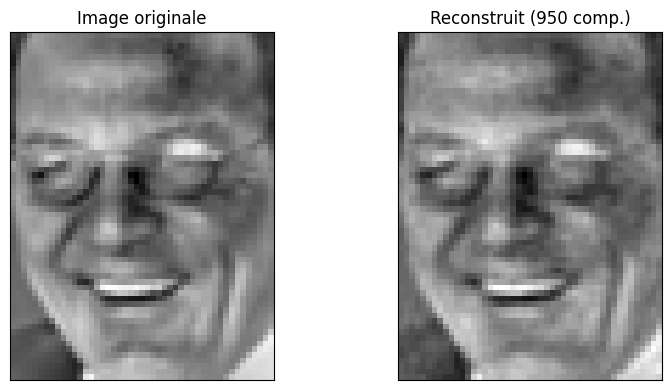

In [14]:
print(f"\nTest avec 950 composantes:")
pca_950 = PCA(n_components=950)
pca_950.fit(X_train_scaled)
X_test_comp_950 = pca_950.transform(X_test_scaled)
X_test_reconst_950 = pca_950.inverse_transform(X_test_comp_950)

E_950 = (X_test_reconst_950 - X_test_scaled)**2
error_950 = np.mean(np.sqrt(np.sum(E_950, axis=1)))
print(f"- Erreur de reconstruction avec 950 composantes: {error_950:.6f}")

# Comparaison visuelle
plt.figure(figsize=(12, 4))
idx = 0
plt.subplot(1, 3, 1)
plt.imshow(X_test_scaled[idx].reshape(62, 47), cmap='gray')
plt.title('Image originale')
plt.xticks([])
plt.yticks([])


plt.subplot(1, 3, 2)
plt.imshow(X_test_reconst_950[idx].reshape(62, 47), cmap='gray')
plt.title('Reconstruit (950 comp.)')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

Avec 950 composantes, la reconstruction est quasi parfaite; on ne remarque presque pas de différence.

<h2>Conclusion</h2>

Ce travail pratique a permis d'explorer de manière approfondie les applications de l'analyse en composantes principales dans le contexte de la reconnaissance faciale, révélant plusieurs enseignements majeurs.


Avec seulement 100 Composantes (réduction de 96.6 % sur les dimensions), on a un taux de reconnaissance de 68,01%; ce qui est relativement acceptable.

Avec ces résultats, on voit bien que l’ACP est un outil très utile pour la reconnaissance faciale, notamment en temps réel. Elle permet de réduire fortement le nombre de dimensions tout en gardant l’essentiel de l’information pour bien distinguer les visages. Cela rend les systèmes plus rapides et moins gourmands en ressources, ce qui est un vrai avantage dans la pratique.

